<a href="https://colab.research.google.com/github/411222050-creator/perpustakaan_undira_Mercy-Angelia_411222050/blob/main/perpustakaan_undira_Mercy_Angelia_411222050.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import sqlite3
import pandas as pd

# 1. Membuat koneksi ke database SQLite (file perpustakaan_undira.db)
conn = sqlite3.connect('perpustakaan_undira.db')
cursor = conn.cursor()

# Mengaktifkan dukungan Foreign Key di SQLite
cursor.execute("PRAGMA foreign_keys = ON;")

# Menghapus tabel jika sudah ada sebelumnya (agar bersih saat dijalankan ulang)
cursor.executescript('''
DROP TABLE IF EXISTS peminjaman;
DROP TABLE IF EXISTS buku;
DROP TABLE IF EXISTS anggota;
''')

# Membuat tabel buku, anggota, dan peminjaman
cursor.executescript('''
CREATE TABLE buku (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    judul TEXT NOT NULL,
    penulis TEXT NOT NULL,
    tahun INTEGER NOT NULL
);

CREATE TABLE anggota (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    nama TEXT NOT NULL,
    email TEXT UNIQUE NOT NULL
);

CREATE TABLE peminjaman (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    id_anggota INTEGER NOT NULL,
    id_buku INTEGER NOT NULL,
    tgl_pinjam DATE NOT NULL,
    tgl_kembali DATE,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku) REFERENCES buku(id)
);
''')

# 1a. Menambahkan 5 data buku dan 3 data anggota
data_buku = [
    ('Clean Code', 'Robert C. Martin', 2008),
    ('Introduction to Algorithms', 'Thomas H. Cormen', 2009),
    ('Database System Concepts', 'Abraham Silberschatz', 2019),
    ('Python Crash Course', 'Eric Matthes', 2019),
    ('Artificial Intelligence: A Modern Approach', 'Stuart Russell', 2020)
]
cursor.executemany("INSERT INTO buku (judul, penulis, tahun) VALUES (?, ?, ?);", data_buku)

data_anggota = [
    ('Mercy Angelia', '411222050@mahasiswa.undira.ac.id'),
    ('Budi Santoso', 'budi.santoso@mahasiswa.undira.ac.id'),
    ('Siti Rahmawati', 'siti.rahmawati@mahasiswa.undira.ac.id')
]
cursor.executemany("INSERT INTO anggota (nama, email) VALUES (?, ?);", data_anggota)

# 1b. Menambahkan 4 transaksi peminjaman (minimal 1 tgl_kembali bernilai NULL/None)
data_peminjaman = [
    (1, 1, '2026-10-01', '2026-10-08'), # Mercy meminjam Clean Code (7 hari)
    (1, 3, '2026-10-10', '2026-10-15'), # Mercy meminjam Database System Concepts (5 hari)
    (2, 2, '2026-10-12', '2026-10-22'), # Budi meminjam Intro to Algorithms (10 hari)
    (3, 4, '2026-11-15', None)          # Siti meminjam Python Crash Course (Belum dikembalikan / NULL)
]
cursor.executemany(
    "INSERT INTO peminjaman (id_anggota, id_buku, tgl_pinjam, tgl_kembali) VALUES (?, ?, ?, ?);",
    data_peminjaman
)

conn.commit()
print("Database dan data awal berhasil dibuat!")

Database dan data awal berhasil dibuat!


In [12]:
# 1c. Menampilkan daftar peminjaman lengkap menggunakan operasi JOIN
query_1c = '''
SELECT
    p.id AS id_peminjaman,
    a.nama AS nama_anggota,
    b.judul AS judul_buku,
    p.tgl_pinjam,
    p.tgl_kembali
FROM peminjaman p
JOIN anggota a ON p.id_anggota = a.id
JOIN buku b ON p.id_buku = b.id;
'''

print("=== 1c. Daftar Peminjaman Lengkap ===")
df_peminjaman = pd.read_sql_query(query_1c, conn)
display(df_peminjaman)

# 1d. Menghitung jumlah total buku yang dipinjam oleh masing-masing anggota
query_1d = '''
SELECT
    a.id AS id_anggota,
    a.nama AS nama_anggota,
    COUNT(p.id) AS total_buku_dipinjam
FROM anggota a
LEFT JOIN peminjaman p ON a.id = p.id_anggota
GROUP BY a.id, a.nama
ORDER BY total_buku_dipinjam DESC;
'''

print("\n=== 1d. Total Buku Dipinjam per Anggota ===")
df_total_pinjam = pd.read_sql_query(query_1d, conn)
display(df_total_pinjam)

=== 1c. Daftar Peminjaman Lengkap ===


,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Mercy Angelia,Clean Code,2026-10-01,2026-10-08
1,2,Mercy Angelia,Database System Concepts,2026-10-10,2026-10-15
2,3,Budi Santoso,Introduction to Algorithms,2026-10-12,2026-10-22
3,4,Siti Rahmawati,Python Crash Course,2026-11-15,None



=== 1d. Total Buku Dipinjam per Anggota ===


,id_anggota,nama_anggota,total_buku_dipinjam
0,1,Mercy Angelia,2
1,2,Budi Santoso,1
2,3,Siti Rahmawati,1


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# 2a. Membuat DataFrame pandas dari hasil query SQL (menggunakan df_peminjaman & df_total_pinjam)
df_eksplorasi = df_peminjaman.copy()

# 2b. Eksplorasi data sederhana: Menghitung durasi peminjaman (dalam hari)
# Konversi kolom tanggal ke tipe datetime
df_eksplorasi['tgl_pinjam'] = pd.to_datetime(df_eksplorasi['tgl_pinjam'])
df_eksplorasi['tgl_kembali'] = pd.to_datetime(df_eksplorasi['tgl_kembali'])

# Menghitung selisih hari (untuk yang belum kembali/NaT, durasinya akan bernilai NaN)
df_eksplorasi['durasi_hari'] = (df_eksplorasi['tgl_kembali'] - df_eksplorasi['tgl_pinjam']).dt.days

# Menambahkan kolom status peminjaman untuk identifikasi pola
df_eksplorasi['status'] = df_eksplorasi['tgl_kembali'].apply(
    lambda x: 'Sudah Dikembalikan' if pd.notnull(x) else 'Sedang Dipinjam'
)

print("=== Tabel Hasil Eksplorasi Data ===")
display(df_eksplorasi)

# Ringkasan Statistik & Pola
rata_rata_durasi = df_eksplorasi['durasi_hari'].mean()
buku_belum_kembali = df_eksplorasi[df_eksplorasi['status'] == 'Sedang Dipinjam'].shape[0]

print(f"\nInsight Eksplorasi Data:")
print(f"- Rata-rata durasi peminjaman (untuk buku yang sudah kembali): {rata_rata_durasi:.1f} hari")
print(f"- Jumlah transaksi aktif (belum dikembalikan): {buku_belum_kembali} transaksi")
print(f"- Anggota paling aktif meminjam: {df_total_pinjam.iloc[0]['nama_anggota']} ({df_total_pinjam.iloc[0]['total_buku_dipinjam']} buku)")

=== Tabel Hasil Eksplorasi Data ===


,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali,durasi_hari,status
0,1,Mercy Angelia,Clean Code,2026-10-01,2026-10-08,7.0,Sudah Dikembalikan
1,2,Mercy Angelia,Database System Concepts,2026-10-10,2026-10-15,5.0,Sudah Dikembalikan
2,3,Budi Santoso,Introduction to Algorithms,2026-10-12,2026-10-22,10.0,Sudah Dikembalikan
3,4,Siti Rahmawati,Python Crash Course,2026-11-15,NaT,NaN,Sedang Dipinjam



Insight Eksplorasi Data:
- Rata-rata durasi peminjaman (untuk buku yang sudah kembali): 7.3 hari
- Jumlah transaksi aktif (belum dikembalikan): 1 transaksi
- Anggota paling aktif meminjam: Mercy Angelia (2 buku)


/tmp/ipykernel_3533/2493396629.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_3533/2493396629.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


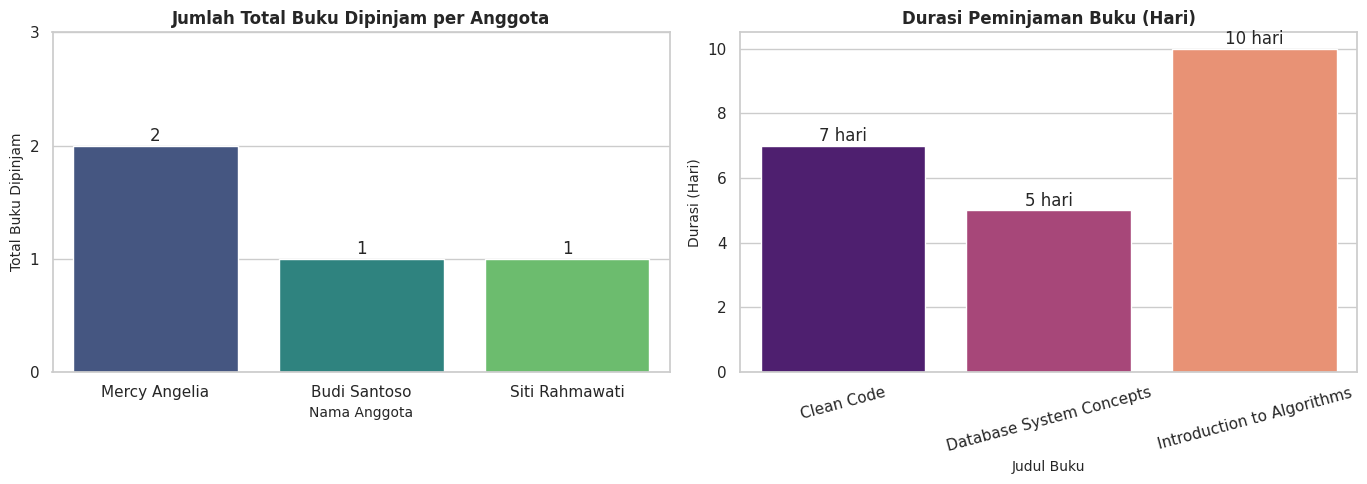

In [14]:
# Mengatur tema visualisasi
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Visualisasi 1: Diagram Batang Jumlah Buku yang Dipinjam per Anggota
sns.barplot(
    data=df_total_pinjam,
    x='nama_anggota',
    y='total_buku_dipinjam',
    palette='viridis',
    ax=axes[0]
)
axes[0].set_title('Jumlah Total Buku Dipinjam per Anggota', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Nama Anggota', fontsize=10)
axes[0].set_ylabel('Total Buku Dipinjam', fontsize=10)
axes[0].set_yticks(range(0, df_total_pinjam['total_buku_dipinjam'].max() + 2))

# Menambahkan label angka di atas batang
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 7), textcoords='offset points')

# Visualisasi 2: Diagram Batang / Distribusi Durasi Peminjaman per Judul Buku (yang sudah kembali)
df_kembali = df_eksplorasi.dropna(subset=['durasi_hari'])
sns.barplot(
    data=df_kembali,
    x='judul_buku',
    y='durasi_hari',
    palette='magma',
    ax=axes[1]
)
axes[1].set_title('Durasi Peminjaman Buku (Hari)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Judul Buku', fontsize=10)
axes[1].set_ylabel('Durasi (Hari)', fontsize=10)
axes[1].tick_params(axis='x', rotation=15)

# Menambahkan label angka di atas batang
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_height())} hari",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 7), textcoords='offset points')

plt.tight_layout()
plt.show()

# Menutup koneksi database setelah semua proses selesai
conn.close()